# Module 2: Phát hiện Vùng Biển số & Hiệu chỉnh Hình học (Slide 2, 7, 9, 11)

Notebook này trình bày thuật toán định vị biển số xe máy Việt Nam (2 dòng) không dùng mạng học sâu:
1. **Toán tử đạo hàm bậc nhất Sobel dọc $|G_x|$ (Slide 2 & 9):** Khai thác mật độ nét đứng dày đặc của dãy chữ số trên biển số.
2. **Phép toán Hình thái học Top-Hat, Black-Hat & Closing (Slide 9 & 11):** Làm nổi bật các nét chữ tối trên nền biển số sáng trắng và gom cụm thành khối chữ nhật đặc.
3. **Lọc vùng ứng viên theo đặc trưng hình học (Slide 11):** Tỷ lệ khung hình $\text{Aspect Ratio} = W/H \in [1.0, 1.62]$, độ lấp đầy $\text{Extent} = A_{\text{contour}} / (W \cdot H) > 0.68$, và năng lượng biên nội vùng.
4. **Hiệu chỉnh góc nghiêng bằng Biến đổi Affine (Slide 7):** Xoay thẳng biển số theo góc của hình chữ nhật bao nhỏ nhất (`minAreaRect`) và chuẩn hóa về kích thước $160 \times 128$.

In [2]:
import sys, os, cv2
from IPython.display import Image, display
sys.path.insert(0, os.path.abspath('..'))

from src.detection import detect_license_plate, deskew_and_crop_plate
from src.pipeline import load_dataset

records = load_dataset('../dataset')
detected_count = 0
for r in records:
    im = cv2.imread(r['img_path'])
    if detect_license_plate(im) is not None:
        detected_count += 1
print(f'Detection Rate across entire dataset: {detected_count}/{len(records)} ({detected_count/len(records)*100:.2f}%)')

Detection Rate across entire dataset: 116/116 (100.00%)


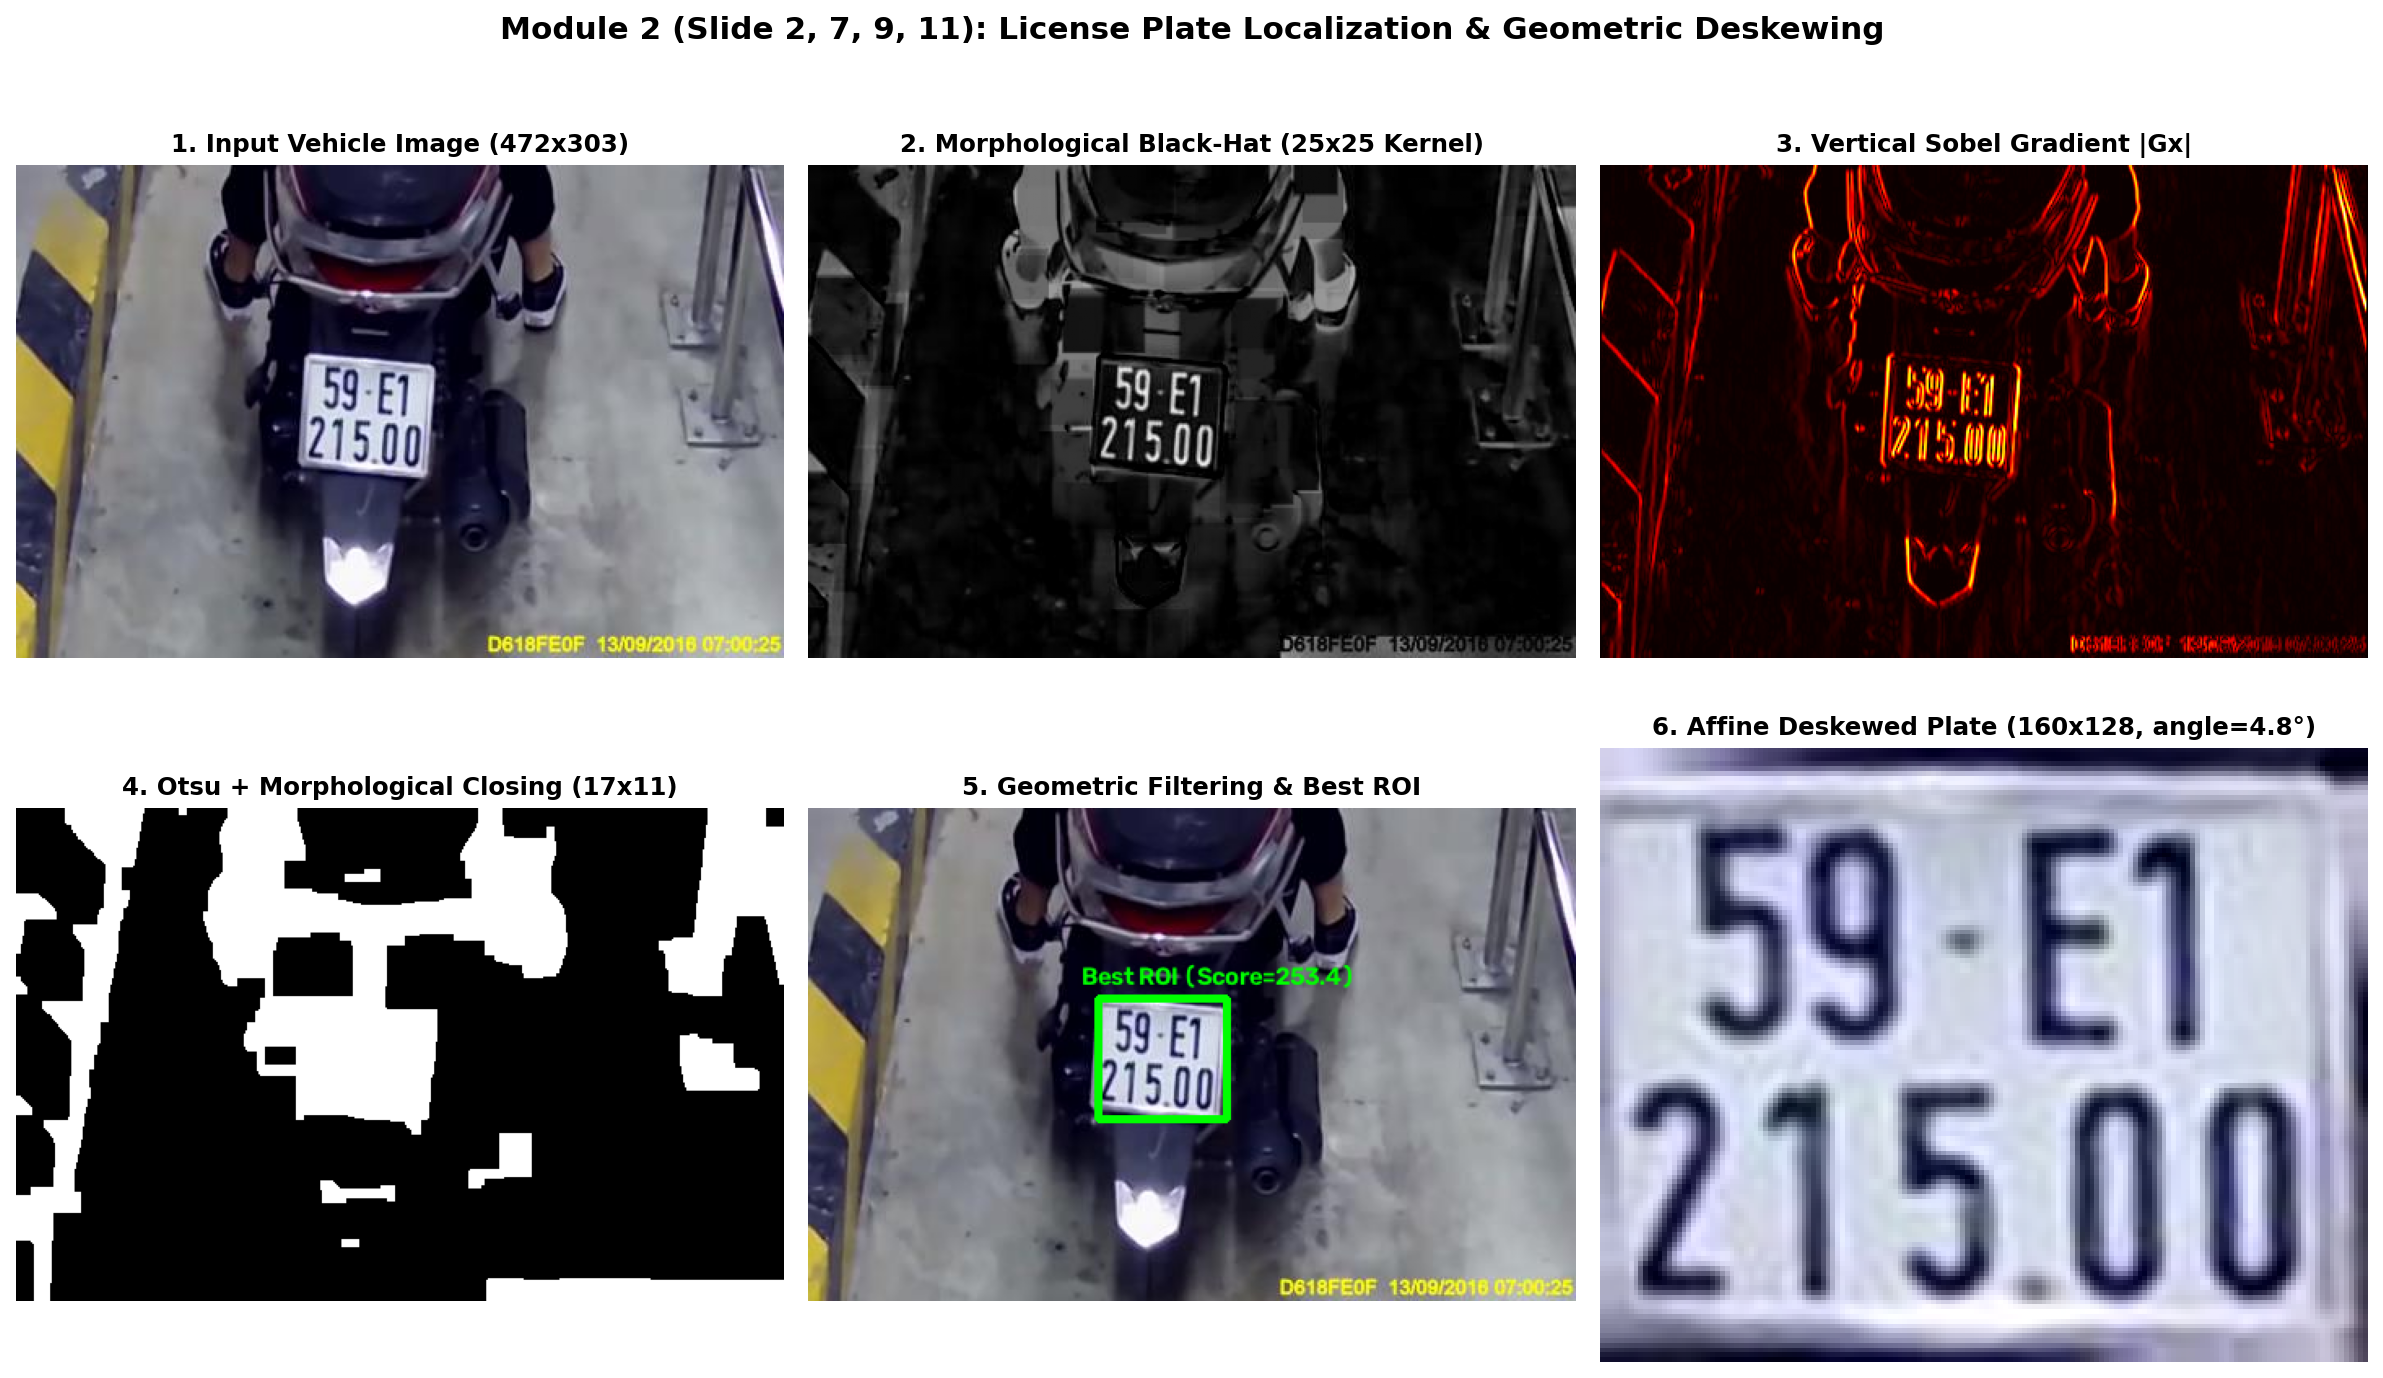

In [3]:
# Minh họa từng bước trung gian của Module 2: Ảnh gốc -> Black-Hat -> Sobel |Gx| -> Closing -> Lọc hình học -> Deskew ROI
display(Image('../outputs/fig04_plate_detection_steps.png'))